## Download the data

In [384]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Data Preparation and Cleaning
* Look at some information about the data and columns
* Fix any missing or incorrect values

In [387]:
campaigns_df = pd.read_csv('data/campaigns.csv')
campaigns_df.head()

,id,campaign_type,channel,topic,started_at,finished_at,total_count,ab_test,warmup_mode,hour_limit,subject_length,subject_with_personalization,subject_with_deadline,subject_with_emoji,subject_with_bonuses,subject_with_discount,subject_with_saleout,is_test,position
0,63,bulk,mobile_push,sale out,2021-04-30 07:22:36.615023,2021-04-30 07:23:41,48211.0,NaN,False,NaN,146.0,False,False,True,False,False,False,NaN,NaN
1,64,bulk,mobile_push,sale out,2021-04-30 09:02:50.817227,2021-04-30 09:04:08,1037337.0,NaN,False,NaN,97.0,False,False,True,False,False,False,NaN,NaN
2,78,bulk,mobile_push,sale out,2021-05-06 07:14:10.533318,2021-05-06 07:15:17,70080.0,NaN,False,NaN,146.0,False,False,True,False,False,False,NaN,NaN
3,79,bulk,mobile_push,sale out,2021-05-06 09:03:56.486750,2021-05-06 09:42:15,921838.0,NaN,False,NaN,97.0,False,False,True,False,False,False,NaN,NaN
4,89,bulk,mobile_push,NaN,2021-05-07 11:54:06.168664,2021-05-07 11:54:38,45503.0,NaN,False,NaN,109.0,False,True,True,False,False,False,NaN,NaN


In [389]:
campaigns_df.describe()

,id,total_count,hour_limit,subject_length,position
count,1907.000000,1.824000e+03,31.000000,1880.000000,24.000000
mean,6122.944415,3.741295e+05,64874.193548,94.340426,6.333333
std,3847.749021,8.198459e+05,184639.986582,28.482613,4.536487
min,26.000000,1.000000e+00,300.000000,4.000000,0.000000
25%,2933.500000,8.467500e+02,6500.000000,92.000000,2.750000
50%,6078.000000,2.006500e+03,10000.000000,96.000000,5.500000
75%,8964.500000,2.820332e+05,35500.000000,112.000000,10.000000
max,25007.000000,5.371769e+06,1000000.000000,185.000000,14.000000


In [391]:
campaigns_df.isnull().sum()

id                                 0
campaign_type                      0
channel                            0
topic                             30
started_at                        83
finished_at                       99
total_count                       83
ab_test                         1895
warmup_mode                       77
hour_limit                      1876
subject_length                    27
subject_with_personalization      27
subject_with_deadline             27
subject_with_emoji                27
subject_with_bonuses              27
subject_with_discount             27
subject_with_saleout              27
is_test                         1880
position                        1883
dtype: int64

In [393]:
# # percentage of missing values
# missing_percentages = campaigns_df.isna().sum().sort_values(ascending=False) / len(campaigns_df)
# missing_percentages

In [395]:
# missing_percentages[missing_percentages != 0].plot(kind='barh')

### Work with 'ab_test' column

### Work with 'Topic' column
We started by analyzing the distribution of the topic column across different campaign_type categories (bulk, transactional, trigger). After identifying missing values in the topic column, we implemented a strategy to fill them based on the most common topic within each campaign_type.

To validate the correctness of our approach, we compared the distributions of topic before and after filling the missing values. We observed that the most frequent topics slightly increased in proportion, while less common ones showed minor decreases, confirming that our method preserved the overall structure of the data.

This process ensured that missing values were filled logically and consistently, maintaining the integrity of the dataset.

In [399]:
original_campaigns_df = campaigns_df.copy()

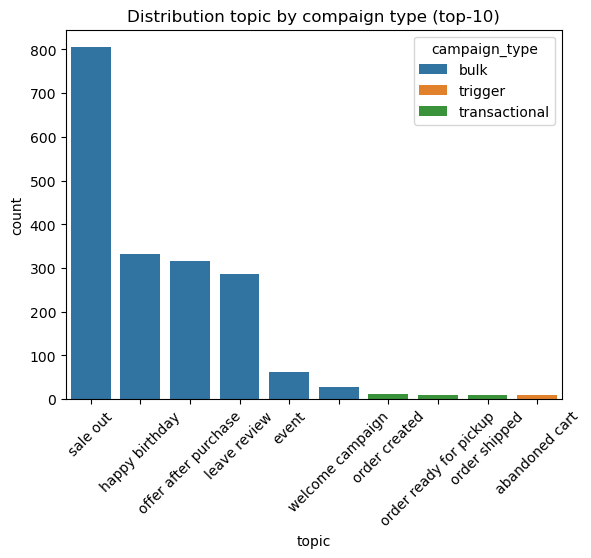

In [454]:
top_n = 10 
top_topics = campaigns_df["topic"].value_counts().index[:top_n]

sns.countplot(data=campaigns_df[campaigns_df["topic"].isin(top_topics)], 
              x="topic", hue="campaign_type", 
              order=top_topics)
plt.xticks(rotation=45)
plt.title("Distribution topic by compaign type (top-10)")
plt.show()

In [402]:
most_common_topics = campaigns_df.groupby('campaign_type')['topic'].agg(lambda x: x.mode()[0])

campaigns_df['topic'] = campaigns_df.apply(
    lambda row: most_common_topics[row['campaign_type']] if pd.isna(row['topic']) else row['topic'],
    axis=1
)

In [405]:
before = original_campaigns_df.groupby("campaign_type")["topic"].value_counts(normalize=True)
after = campaigns_df.groupby("campaign_type")["topic"].value_counts(normalize=True)
comparison = after - before
print(comparison.dropna())

campaign_type  topic                     
bulk           sale out                      0.008073
               happy birthday               -0.002615
               offer after purchase         -0.002489
               leave review                 -0.002260
               event                        -0.000496
               welcome campaign             -0.000213
transactional  order created                 0.015918
               order ready for pickup       -0.004082
               order shipped                -0.004082
               order reminder               -0.003673
               order pickup still pending   -0.001633
               order cancelled              -0.000816
               bonuses expired              -0.000408
               profile updated              -0.000408
               welcome letter               -0.000408
               wish list status             -0.000408
trigger        abandoned cart                0.083333
               abandoned view           

### Work with 'Total_count' column
We examined the total_count distribution by plotting its histogram. During the analysis, we found missing values and outliers. The median was chosen to fill in the gaps, since the distribution had significant outliers, and the average could distort the data. After filling NaN with the median value, we checked the correctness of the changes by comparing the (mean, median,std) before and after, and also making sure that the median remained unchanged.

<Axes: xlabel='total_count', ylabel='Count'>

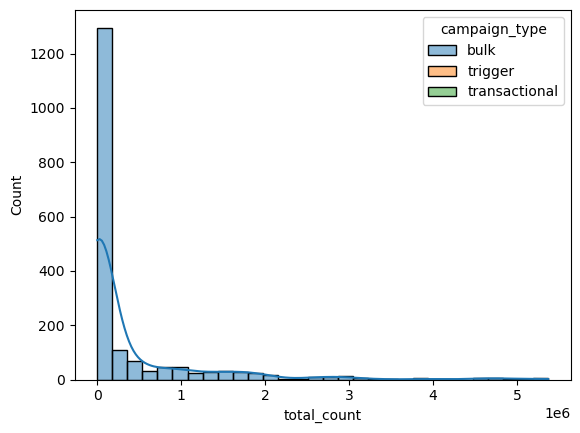

In [408]:
sns.histplot(data=campaigns_df, x="total_count", hue="campaign_type", bins=30, kde=True, multiple="stack")

In [409]:
print(campaigns_df["total_count"].describe())

count    1.824000e+03
mean     3.741295e+05
std      8.198459e+05
min      1.000000e+00
25%      8.467500e+02
50%      2.006500e+03
75%      2.820332e+05
max      5.371769e+06
Name: total_count, dtype: float64


In [412]:
campaigns_df['total_count'] = campaigns_df['total_count'].fillna(campaigns_df['total_count'].median())

In [414]:
print(campaigns_df["total_count"].describe())

count    1.907000e+03
mean     3.579332e+05
std      8.053851e+05
min      1.000000e+00
25%      8.865000e+02
50%      2.006500e+03
75%      2.495795e+05
max      5.371769e+06
Name: total_count, dtype: float64


### Work with 'Warmup_mode' column
Filling missing values in the 'warmup_mode' column with the most frequent value (mode).

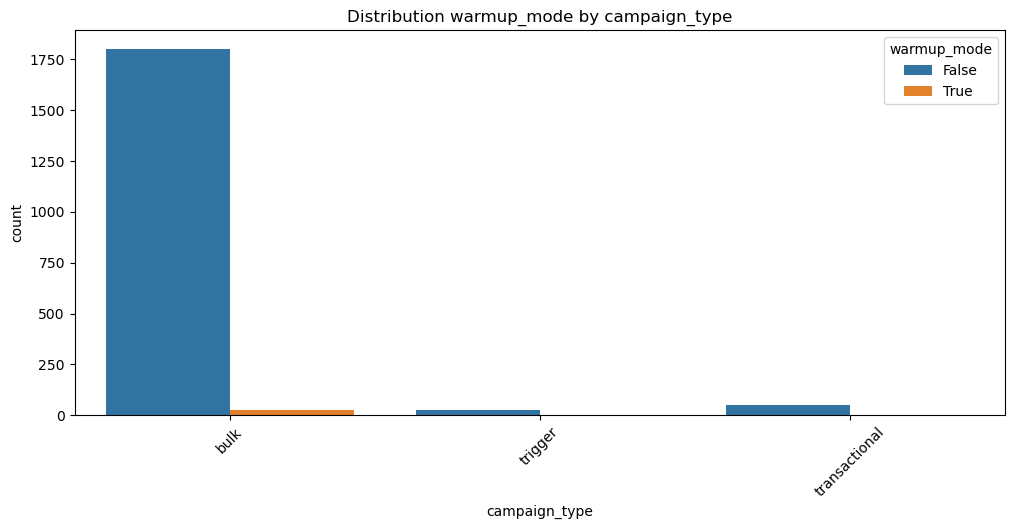

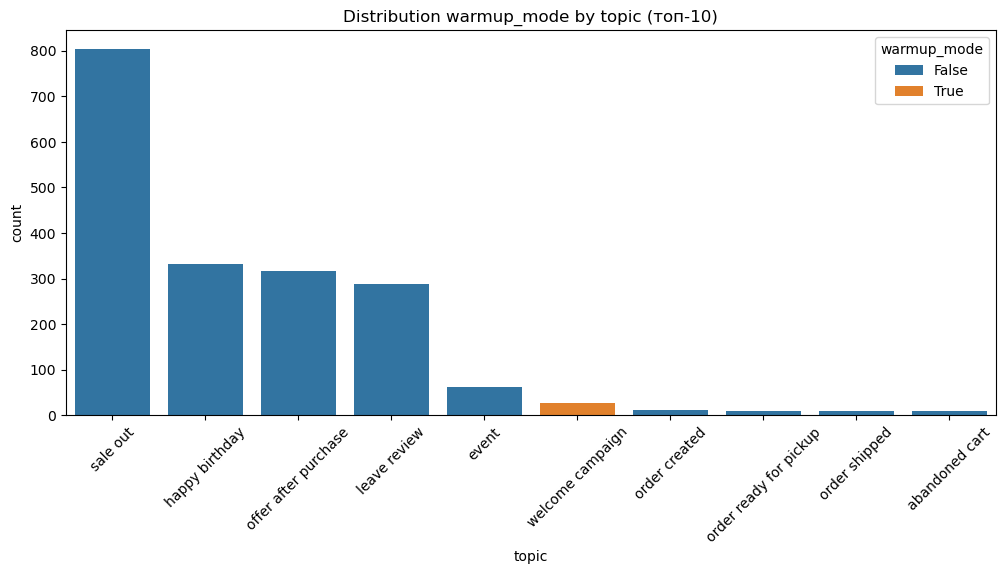

In [448]:
plt.figure(figsize=(12, 5))
sns.countplot(data=campaigns_df, x="campaign_type", hue="warmup_mode")
plt.title("Distribution warmup_mode by campaign_type")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 5))
sns.countplot(data=campaigns_df, x="topic", hue="warmup_mode", order=campaigns_df["topic"].value_counts().index[:10])
plt.title("Distribution warmup_mode by topic (топ-10)")
plt.xticks(rotation=45)
plt.show()

In [418]:
campaigns_df["warmup_mode"] = False
campaigns_df.loc[campaigns_df["topic"] == "welcome campaign", "warmup_mode"] = True
print(campaigns_df['warmup_mode'].isna().sum())

0


### Work with Subjects columns
I analyzed the subject_length column in the campaigns dataset, identified missing values, and filled them based on data distribution. To validate the imputation, i visualized the distribution before and after filling NaNs, ensuring no significant distortions. Finally, i confirmed that no missing values remained and maintained data consistency.

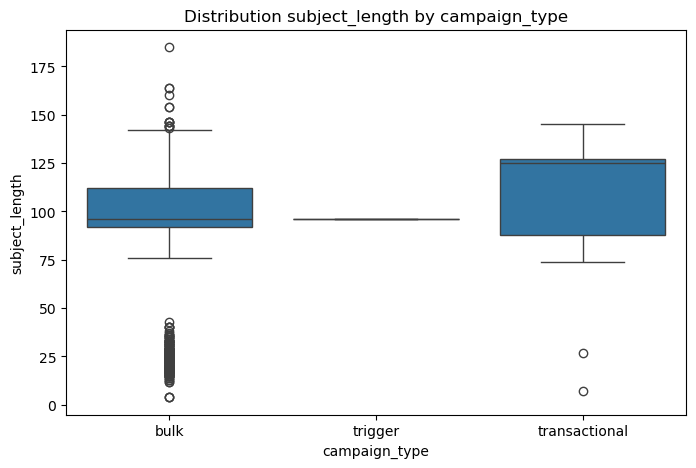

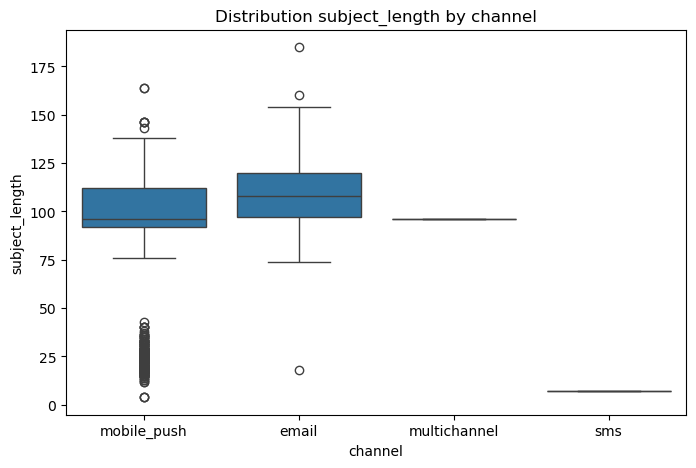

In [441]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=campaigns_df['campaign_type'], y=campaigns_df['subject_length'])
plt.title("Distribution subject_length by campaign_type")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x=campaigns_df['channel'], y=campaigns_df['subject_length'])
plt.title("Distribution subject_length by channel")
plt.show()


In [436]:
campaigns_df['subject_length'] = campaigns_df.groupby('channel')['subject_length'].transform(lambda x: x.fillna(x.median()))

campaigns_df['subject_length'] = campaigns_df['subject_length'].fillna(campaigns_df['subject_length'].median())

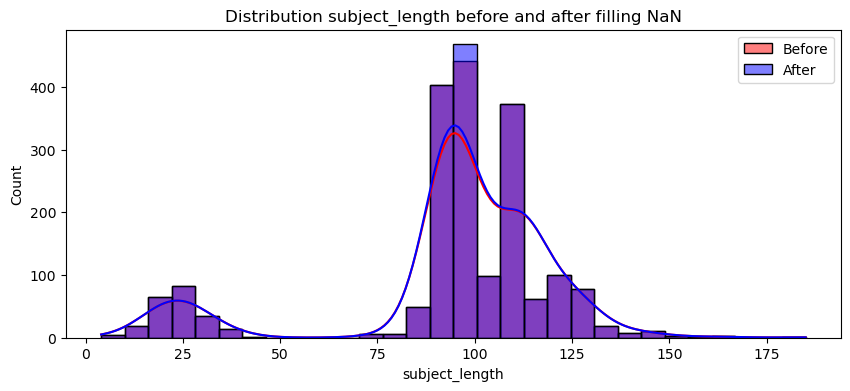

In [445]:
plt.figure(figsize=(10, 4))
sns.histplot(original_campaigns_df['subject_length'], bins=30, kde=True, color="red", alpha=0.5, label="Before")
sns.histplot(campaigns_df['subject_length'], bins=30, kde=True, color="blue", alpha=0.5, label="After")
plt.legend()
plt.title("Distribution subject_length before and after filling NaN")
plt.show()


### Work with 'start_at' and 'finished_at' columns

In [343]:
campaigns_df.isna().sum()

id                                 0
campaign_type                      0
channel                            0
topic                              0
started_at                        83
finished_at                       99
total_count                        0
ab_test                         1895
warmup_mode                        0
hour_limit                      1876
subject_length                    27
subject_with_personalization      27
subject_with_deadline             27
subject_with_emoji                27
subject_with_bonuses              27
subject_with_discount             27
subject_with_saleout              27
is_test                         1880
position                        1883
dtype: int64